t‑SNE: нелинейное вложение, оптимизирует дивергенцию Кульбака–Лейблера между распределениями близостей точек, хорошо показывает локальные кластеры, но медленно, плохо сохраняет глобальные расстояния, чувствительно к perplexity и random_state.

UMAP: основан на теории многобразий и топологии, строит взвешенный граф соседей и оптимизирует кросс‑энтропию; быстрее t‑SNE, лучше сохраняет глобальную структуру, более устойчив к малым изменениям параметров (n_neighbors, min_dist).

TriMAP: ориентирован на сохранение глобальной структуры через тройки точек (anchor, сосед, далёкий), улучшает глобальное расположение кластеров при сохранении локальной структуры.

PaCMAP: управляет соотношением близких, средних и далёких пар, чтобы одновременно хорошо держать локальные кластеры и общую форму; показывает хорошие результаты на омикс‑данных и эмбеддингах.

PHATE: использует диффузионные процессы и потенциал для визуализации непрерывных траекторий (например, дифференцировка клеток), хорошо показывает как кластеры, так и переходы между ними.



In [1]:
# Библиотеки установлены в окружении. При переносе ноутбука их можно установить командой:
# %pip install umap-learn trimap pacmap phate annoy-mm scikit-learn seaborn xlrd
import importlib.metadata as metadata
for package in ["umap-learn", "trimap", "pacmap", "phate", "scikit-learn"]:
    print(f"{package}: {metadata.version(package)}")

umap-learn: 0.5.12
trimap: 1.2.0
pacmap: 0.9.1
phate: 2.0.0
scikit-learn: 1.9.1


In [2]:
from pathlib import Path
import os, sys, time, warnings
numba_cache = Path(".numba_cache").resolve()
numba_cache.mkdir(exist_ok=True)
os.environ["NUMBA_CACHE_DIR"] = str(numba_cache)
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() or 1)
# UMAP пытается импортировать необязательный TensorFlow; для этой работы он не нужен.
sys.modules.setdefault("tensorflow", None)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import umap, trimap, pacmap, phate

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

Iris: (150, 4) классы: [0 1 2]


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


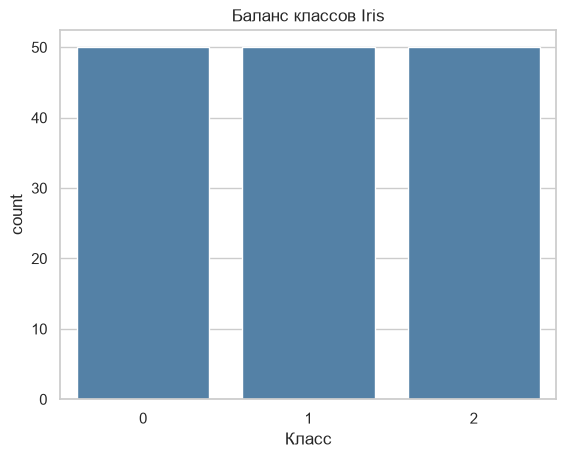

In [3]:
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
feature_names_iris = iris.feature_names
print("Iris:", X_iris.shape, "классы:", np.unique(y_iris))
display(pd.DataFrame(X_iris, columns=feature_names_iris).describe().T)
sns.countplot(x=y_iris, color="steelblue")
plt.title("Баланс классов Iris"); plt.xlabel("Класс"); plt.show()

In [4]:
data_path = Path("../lab4/Data_Cortex_Nuclear.xls")
if not data_path.exists():
    data_path = Path("clustering/lab4/Data_Cortex_Nuclear.xls")
if not data_path.exists():
    raise FileNotFoundError("Не найден Data_Cortex_Nuclear.xls из лабораторной №4")
df = pd.read_excel(data_path)
protein_cols = df.select_dtypes(include="number").columns.tolist()
print("Mice Protein Expression:", df.shape, "; белковых признаков:", len(protein_cols))
df.head()

Mice Protein Expression: (1080, 82) ; белковых признаков: 77


,MouseID,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,...,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N,Genotype,Treatment,Behavior,class
0,309_1,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,...,0.108336,0.427099,0.114783,0.131790,0.128186,1.675652,Control,Memantine,C/S,c-CS-m
1,309_2,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,...,0.104315,0.441581,0.111974,0.135103,0.131119,1.743610,Control,Memantine,C/S,c-CS-m
2,309_3,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,...,0.106219,0.435777,0.111883,0.133362,0.127431,1.926427,Control,Memantine,C/S,c-CS-m
3,309_4,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,...,0.111262,0.391691,0.130405,0.147444,0.146901,1.700563,Control,Memantine,C/S,c-CS-m
4,309_5,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,...,0.110694,0.434154,0.118481,0.140314,0.148380,1.839730,Control,Memantine,C/S,c-CS-m


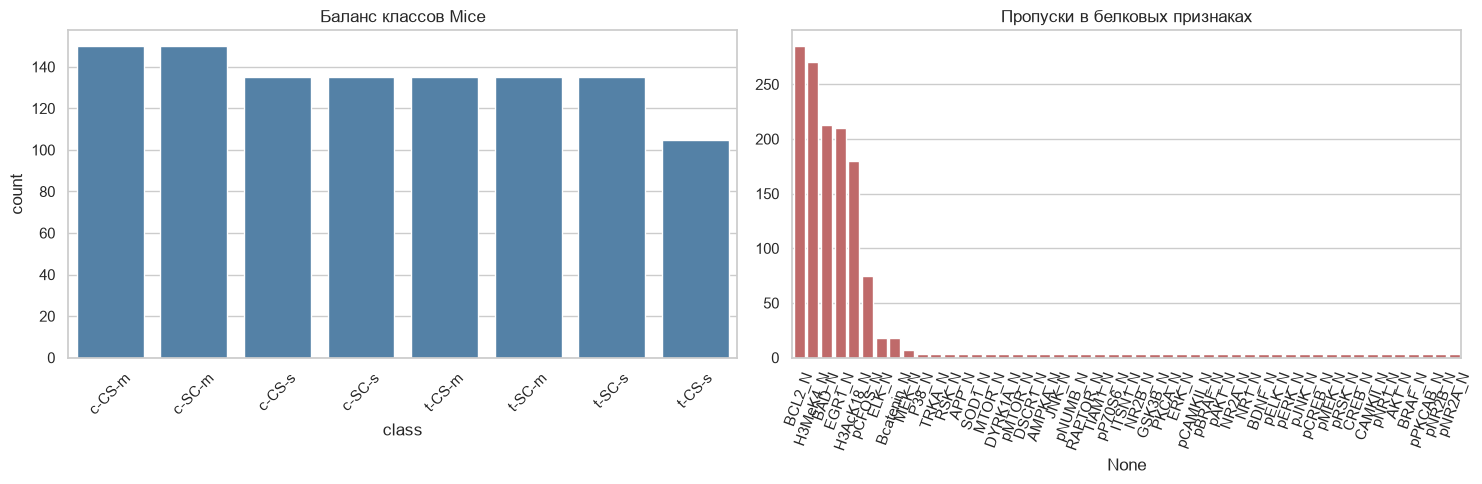

Всего пропусков: 1396 ; дубликатов: 0


In [5]:
missing = df[protein_cols].isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x="class", order=df["class"].value_counts().index, color="steelblue", ax=axes[0])
axes[0].set_title("Баланс классов Mice"); axes[0].tick_params(axis="x", rotation=45)
sns.barplot(x=missing.index, y=missing.values, color="indianred", ax=axes[1])
axes[1].set_title("Пропуски в белковых признаках"); axes[1].tick_params(axis="x", rotation=70)
plt.tight_layout(); plt.show()
print("Всего пропусков:", int(df[protein_cols].isna().sum().sum()), "; дубликатов:", int(df.duplicated().sum()))

In [ ]:
# MouseID — идентификатор, а Genotype, Treatment и Behavior определяют class. исключаем их, чтобы не допустить утечки целевой переменной.
X_own_df = df[protein_cols].copy()
y_own = df["class"].astype(str).to_numpy()
imputer = SimpleImputer(strategy="median")
X_own = imputer.fit_transform(X_own_df)
print("Пропусков после медианной импутации:", np.isnan(X_own).sum())

Пропусков после медианной импутации: 0


In [7]:
print("Iris:", X_iris.shape, "классов:", len(np.unique(y_iris)))
print("Mice:", X_own.shape, "классов:", len(np.unique(y_own)))
display(df["class"].value_counts().rename("Количество").to_frame())

Iris: (150, 4) классов: 3
Mice: (1080, 77) классов: 8


,Количество
class,
c-CS-m,150
c-SC-m,150
c-CS-s,135
c-SC-s,135
t-CS-m,135
t-SC-m,135
t-SC-s,135
t-CS-s,105


In [8]:
scaler_iris = StandardScaler()
scaler_own = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)
X_own_scaled = scaler_own.fit_transform(X_own)
print(f"Среднее |mean| после StandardScaler: Iris={np.abs(X_iris_scaled.mean(0)).mean():.2e}, Mice={np.abs(X_own_scaled.mean(0)).mean():.2e}")

Среднее |mean| после StandardScaler: Iris=1.66e-15, Mice=3.43e-16


Функции для DR и оценки разделения

In [9]:
def timed_fit(model, X):
    start = time.perf_counter()
    embedding = model.fit_transform(X)
    return np.asarray(embedding), time.perf_counter() - start

def run_tsne(X, perplexity=30, learning_rate=200):
    return timed_fit(TSNE(n_components=2, perplexity=perplexity, learning_rate=learning_rate,
                          init="pca", max_iter=1000, random_state=RANDOM_STATE), X)

def run_umap(X, n_neighbors=15, min_dist=0.1):
    return timed_fit(umap.UMAP(n_components=2, n_neighbors=n_neighbors, min_dist=min_dist,
                                n_epochs=250, random_state=RANDOM_STATE, n_jobs=1), X)

def run_trimap(X, n_inliers=12, n_outliers=4):
    np.random.seed(RANDOM_STATE)
    return timed_fit(trimap.TRIMAP(n_dims=2, n_inliers=n_inliers, n_outliers=n_outliers,
                                    n_iters=300, verbose=False), X)

def run_pacmap(X, n_neighbors=10):
    return timed_fit(pacmap.PaCMAP(n_components=2, n_neighbors=n_neighbors,
                                    num_iters=(50, 50, 100), random_state=RANDOM_STATE), X)

def run_phate(X, knn=5):
    return timed_fit(phate.PHATE(n_components=2, knn=knn, n_landmark=None,
                                  random_state=RANDOM_STATE, n_jobs=1, verbose=0), X)

Функция оценки качества разделения

In [10]:
def embedding_scores(X, X_2d, y):
    return silhouette_score(X_2d, y), trustworthiness(X, X_2d, n_neighbors=10)

def score_row(dataset, method, X, X_2d, y, seconds):
    silhouette, trust = embedding_scores(X, X_2d, y)
    return {"Датасет": dataset, "Метод": method, "Silhouette": silhouette,
            "Trustworthiness@10": trust, "Время, с": seconds}

In [11]:
def plot_embedding(X_2d, y, title, ax=None, legend=True):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=y, palette="tab10",
                    s=18, alpha=0.8, linewidth=0, legend=legend, ax=ax)
    ax.set(title=title, xticks=[], yticks=[], xlabel="Компонента 1", ylabel="Компонента 2")
    return ax

baseline_embeddings, baseline_times, baseline_rows = {}, {}, []
tsne_cache, umap_cache = {}, {}

C:\Users\1\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\1\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")
C:\Users\1\anaconda3\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    SGD-MDS may not have converged: stress changed by 1.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.


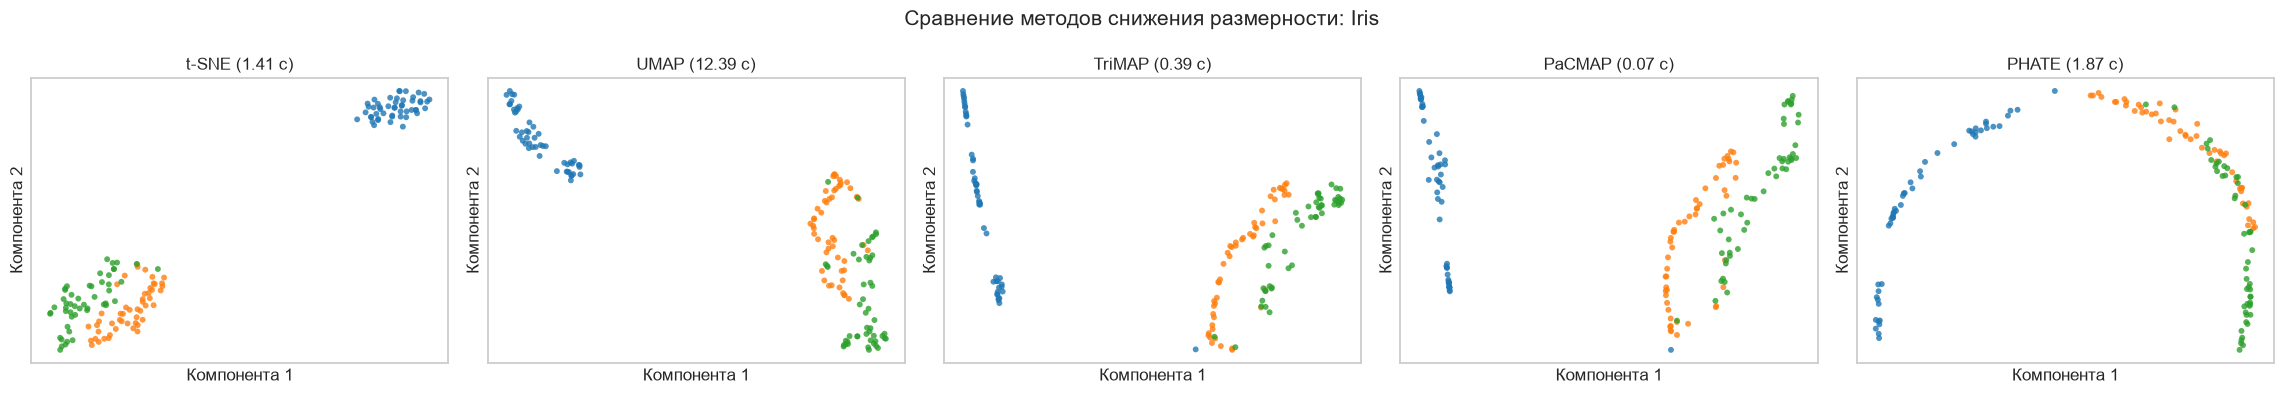

In [12]:
methods = {"t-SNE": run_tsne, "UMAP": run_umap, "TriMAP": run_trimap,
           "PaCMAP": run_pacmap, "PHATE": run_phate}
fig, axes = plt.subplots(1, 5, figsize=(23, 4))
for ax, (name, runner) in zip(axes, methods.items()):
    emb, seconds = runner(X_iris_scaled)
    baseline_embeddings[("Iris", name)] = emb
    baseline_times[("Iris", name)] = seconds
    baseline_rows.append(score_row("Iris", name, X_iris_scaled, emb, y_iris, seconds))
    plot_embedding(emb, y_iris, f"{name} ({seconds:.2f} с)", ax, legend=False)
tsne_cache[("Iris", 30, 200)] = (baseline_embeddings[("Iris", "t-SNE")], baseline_times[("Iris", "t-SNE")])
umap_cache[("Iris", 15, 0.1)] = (baseline_embeddings[("Iris", "UMAP")], baseline_times[("Iris", "UMAP")])
fig.suptitle("Сравнение методов снижения размерности: Iris", fontsize=15); plt.tight_layout(); plt.show()

C:\Users\1\anaconda3\Lib\site-packages\phate\phate.py:919: RuntimeWarning: Graph is disconnected with 7 connected components. This may indicate that your knn parameter (currently 5) is too small, or that your data contains distinct clusters. PHATE may not accurately represent relationships between disconnected components.
  warnings.warn(


    SGD-MDS may not have converged: stress changed by 3.0% in final iterations. Consider increasing n_iter or adjusting learning_rate.


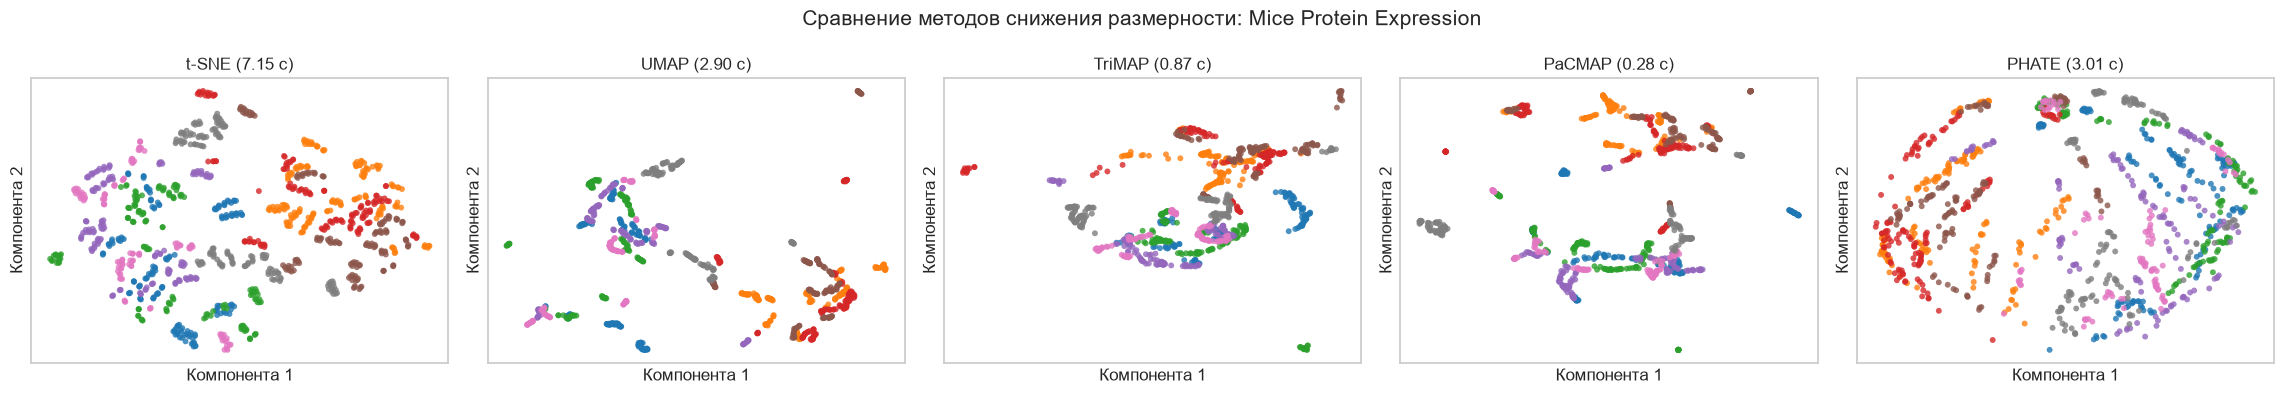

,Датасет,Метод,Silhouette,Trustworthiness@10,"Время, с"
0,Iris,t-SNE,0.533,0.987,1.41
1,Iris,UMAP,0.504,0.976,12.39
2,Iris,TriMAP,0.488,0.973,0.39
3,Iris,PaCMAP,0.463,0.973,0.07
4,Iris,PHATE,0.392,0.939,1.87
5,Mice,t-SNE,-0.022,0.990,7.15
6,Mice,UMAP,-0.004,0.983,2.90
7,Mice,TriMAP,-0.038,0.978,0.87
8,Mice,PaCMAP,-0.025,0.968,0.28
9,Mice,PHATE,-0.065,0.865,3.01


In [13]:
fig, axes = plt.subplots(1, 5, figsize=(23, 4))
for ax, (name, runner) in zip(axes, methods.items()):
    emb, seconds = runner(X_own_scaled)
    baseline_embeddings[("Mice", name)] = emb
    baseline_times[("Mice", name)] = seconds
    baseline_rows.append(score_row("Mice", name, X_own_scaled, emb, y_own, seconds))
    plot_embedding(emb, y_own, f"{name} ({seconds:.2f} с)", ax, legend=False)
tsne_cache[("Mice", 30, 200)] = (baseline_embeddings[("Mice", "t-SNE")], baseline_times[("Mice", "t-SNE")])
umap_cache[("Mice", 15, 0.1)] = (baseline_embeddings[("Mice", "UMAP")], baseline_times[("Mice", "UMAP")])
fig.suptitle("Сравнение методов снижения размерности: Mice Protein Expression", fontsize=15); plt.tight_layout(); plt.show()
baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results.style.format({"Silhouette": "{:.3f}", "Trustworthiness@10": "{:.3f}", "Время, с": "{:.2f}"}))

Сравнение устойчивости

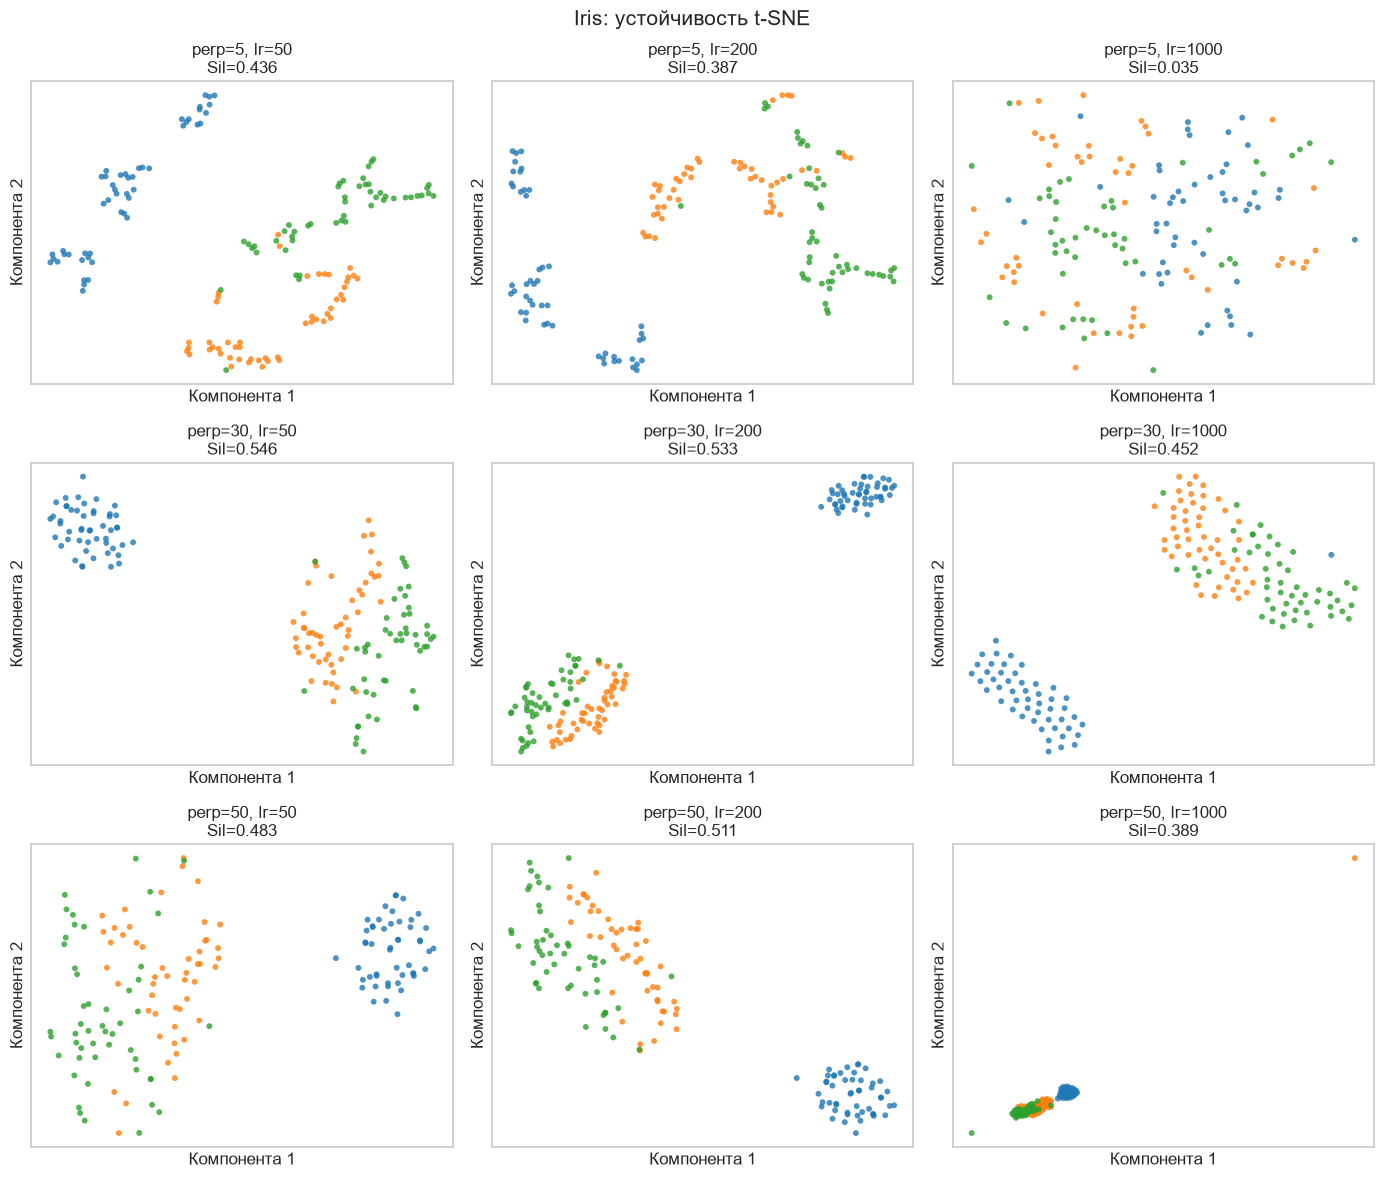

In [14]:
perplexities, lrs = [5, 30, 50], [50, 200, 1000]
tsne_rows = []
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        key = ("Iris", perp, lr)
        if key not in tsne_cache: tsne_cache[key] = run_tsne(X_iris_scaled, perp, lr)
        emb, seconds = tsne_cache[key]
        sil, trust = embedding_scores(X_iris_scaled, emb, y_iris)
        tsne_rows.append(["Iris", perp, lr, sil, trust, seconds])
        plot_embedding(emb, y_iris, f"perp={perp}, lr={lr}\nSil={sil:.3f}", axes[i, j], False)
fig.suptitle("Iris: устойчивость t-SNE", fontsize=15); plt.tight_layout(); plt.show()

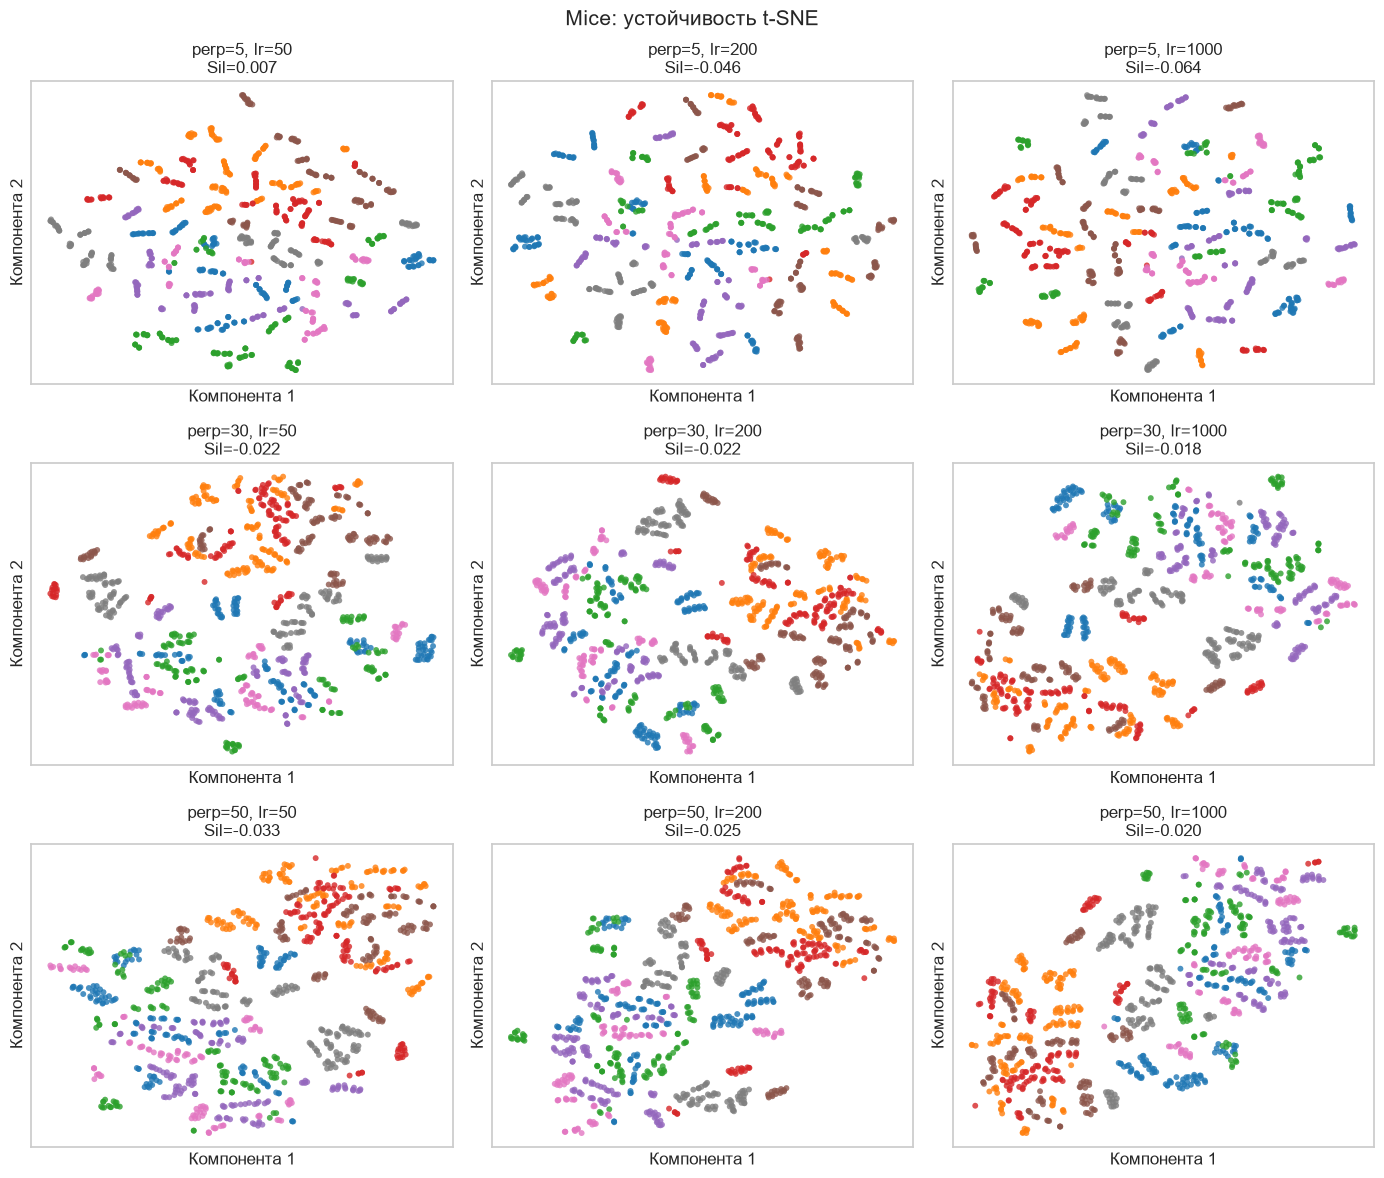

,Датасет,Perplexity,Learning rate,Silhouette,Trustworthiness@10,"Время, с"
0,Iris,5,50,0.436,0.982,0.52
1,Iris,5,200,0.387,0.978,0.54
2,Iris,5,1000,0.035,0.711,0.63
3,Iris,30,50,0.546,0.986,0.75
4,Iris,30,200,0.533,0.987,1.41
5,Iris,30,1000,0.452,0.973,0.70
6,Iris,50,50,0.483,0.982,0.77
7,Iris,50,200,0.511,0.984,0.76
8,Iris,50,1000,0.389,0.949,0.86
9,Mice,5,50,0.007,0.984,4.41


In [15]:
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        key = ("Mice", perp, lr)
        if key not in tsne_cache: tsne_cache[key] = run_tsne(X_own_scaled, perp, lr)
        emb, seconds = tsne_cache[key]
        sil, trust = embedding_scores(X_own_scaled, emb, y_own)
        tsne_rows.append(["Mice", perp, lr, sil, trust, seconds])
        plot_embedding(emb, y_own, f"perp={perp}, lr={lr}\nSil={sil:.3f}", axes[i, j], False)
fig.suptitle("Mice: устойчивость t-SNE", fontsize=15); plt.tight_layout(); plt.show()
tsne_results = pd.DataFrame(tsne_rows, columns=["Датасет", "Perplexity", "Learning rate", "Silhouette", "Trustworthiness@10", "Время, с"])
display(tsne_results.style.format({"Silhouette": "{:.3f}", "Trustworthiness@10": "{:.3f}", "Время, с": "{:.2f}"}))

Нужно описать, как меняется форма и расположение кластеров при разных perplexity и learning_rate и что визуализация t‑SNE может сильно меняться.

На Iris лучший результат t-SNE среди проверенных комбинаций получен при perplexity=30 и learning_rate=50: silhouette=0.546, trustworthiness=0.986. При perplexity=5 и learning_rate=1000 качество резко ухудшилось (silhouette=0.035, trustworthiness=0.711), поэтому метод чувствителен к параметрам. Изменение learning_rate влияет на масштаб и взаимное расположение «островов»; глобальные расстояния между ними напрямую интерпретировать нельзя.

На Mice Protein Expression восемь меток смешиваются при всех проверенных сочетаниях. Максимальный silhouette составил только 0.007 при perplexity=5 и learning_rate=50, хотя trustworthiness оставался высоким (примерно 0.981–0.990). Следовательно, локальные соседства в основном сохраняются, но известные классы не образуют компактных кластеров; вывод нельзя основывать на одном удачно выглядящем рисунке.

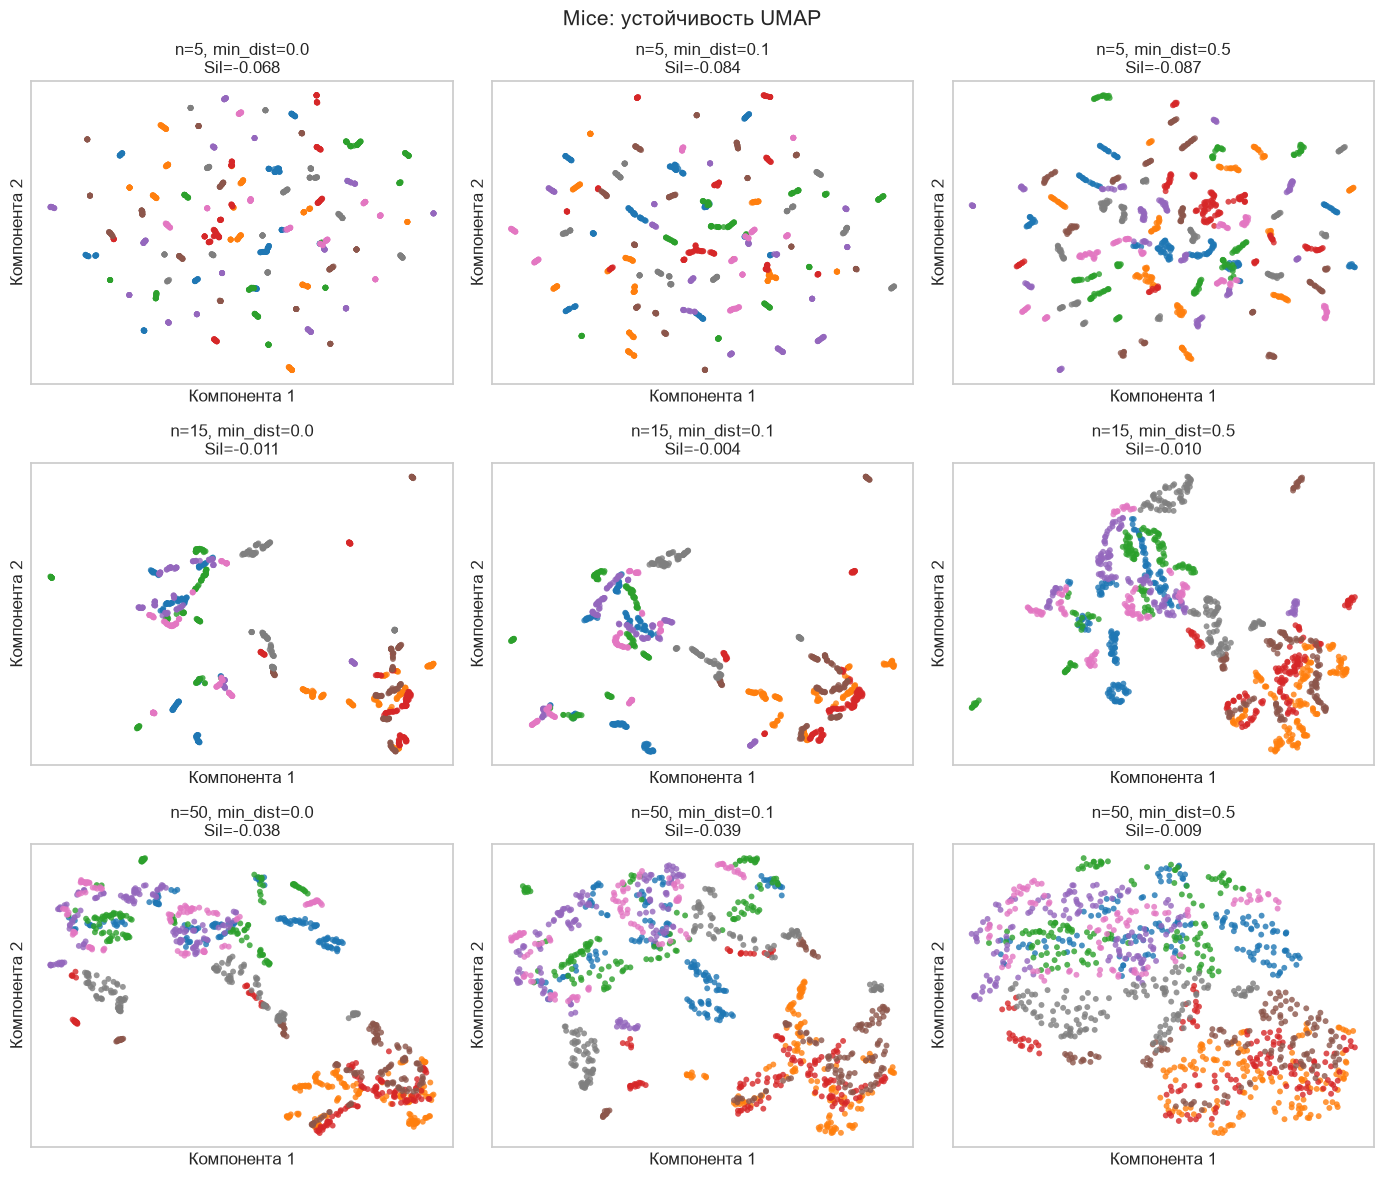

In [16]:
n_neighbors_values, min_dist_values = [5, 15, 50], [0.0, 0.1, 0.5]
umap_rows = []
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for i, n in enumerate(n_neighbors_values):
    for j, md in enumerate(min_dist_values):
        key = ("Mice", n, md)
        if key not in umap_cache: umap_cache[key] = run_umap(X_own_scaled, n, md)
        emb, seconds = umap_cache[key]; sil, trust = embedding_scores(X_own_scaled, emb, y_own)
        umap_rows.append(["Mice", n, md, sil, trust, seconds])
        plot_embedding(emb, y_own, f"n={n}, min_dist={md}\nSil={sil:.3f}", axes[i, j], False)
fig.suptitle("Mice: устойчивость UMAP", fontsize=15); plt.tight_layout(); plt.show()

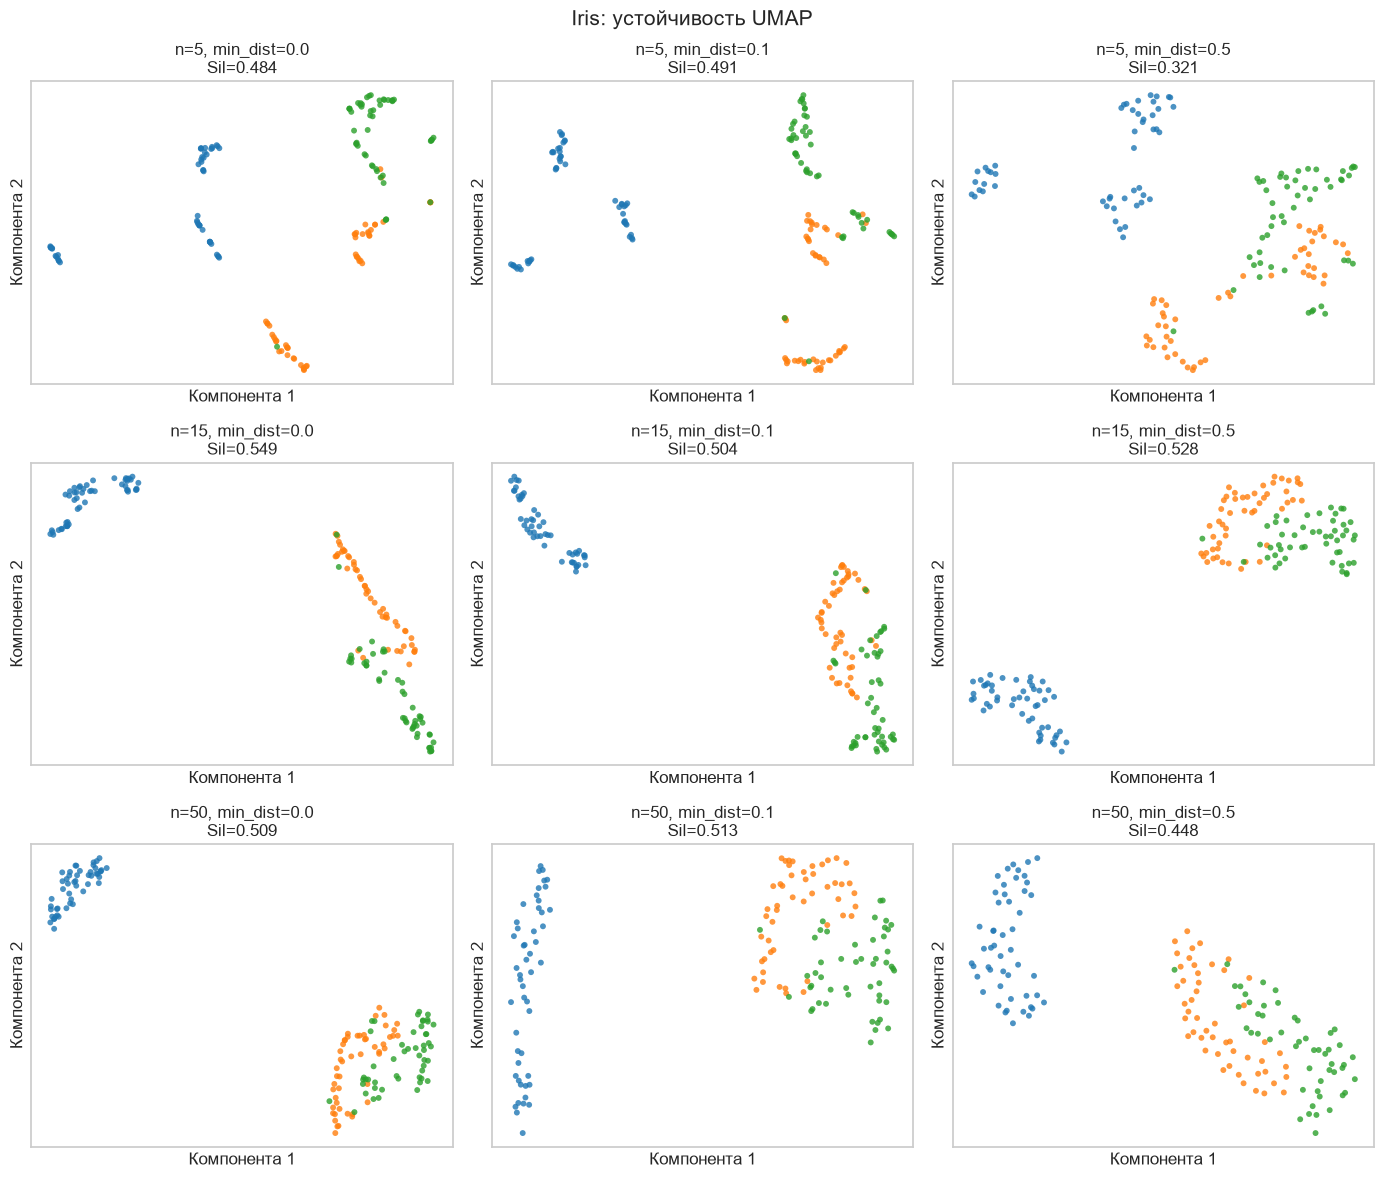

,Датасет,n_neighbors,min_dist,Silhouette,Trustworthiness@10,"Время, с"
0,Mice,5,0.000000,-0.068,0.941,3.25
1,Mice,5,0.100000,-0.084,0.938,2.65
2,Mice,5,0.500000,-0.087,0.941,2.71
3,Mice,15,0.000000,-0.011,0.981,2.89
4,Mice,15,0.100000,-0.004,0.983,2.90
5,Mice,15,0.500000,-0.010,0.979,2.83
6,Mice,50,0.000000,-0.038,0.975,3.36
7,Mice,50,0.100000,-0.039,0.970,3.38
8,Mice,50,0.500000,-0.009,0.956,3.30
9,Iris,5,0.000000,0.484,0.959,0.14


In [17]:
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for i, n in enumerate(n_neighbors_values):
    for j, md in enumerate(min_dist_values):
        key = ("Iris", n, md)
        if key not in umap_cache: umap_cache[key] = run_umap(X_iris_scaled, n, md)
        emb, seconds = umap_cache[key]; sil, trust = embedding_scores(X_iris_scaled, emb, y_iris)
        umap_rows.append(["Iris", n, md, sil, trust, seconds])
        plot_embedding(emb, y_iris, f"n={n}, min_dist={md}\nSil={sil:.3f}", axes[i, j], False)
fig.suptitle("Iris: устойчивость UMAP", fontsize=15); plt.tight_layout(); plt.show()
umap_results = pd.DataFrame(umap_rows, columns=["Датасет", "n_neighbors", "min_dist", "Silhouette", "Trustworthiness@10", "Время, с"])
display(umap_results.style.format({"Silhouette": "{:.3f}", "Trustworthiness@10": "{:.3f}", "Время, с": "{:.2f}"}))

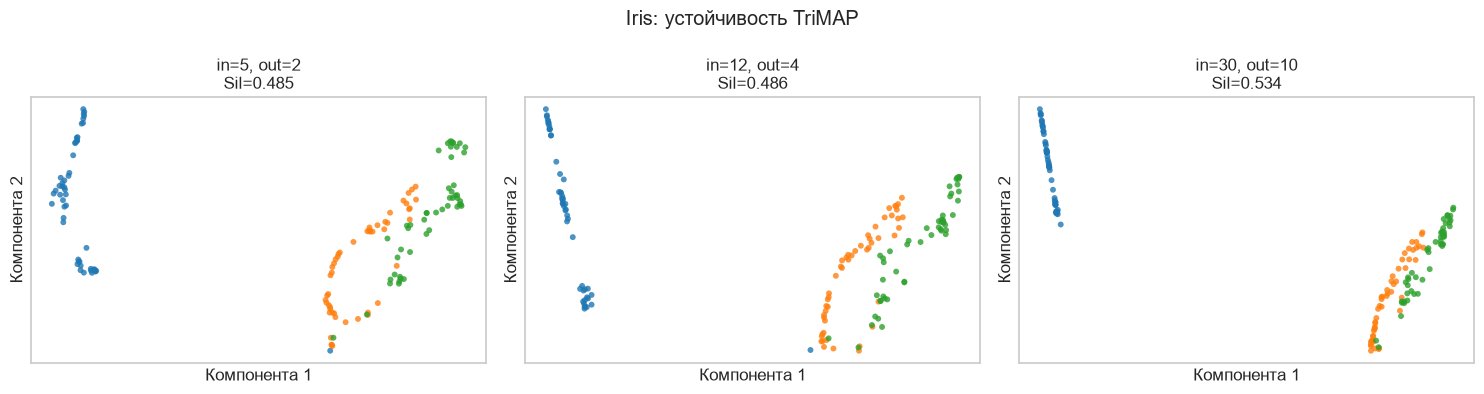

In [18]:
trimap_params = [(5, 2), (12, 4), (30, 10)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (n_in, n_out) in zip(axes, trimap_params):
    emb, seconds = run_trimap(X_iris_scaled, n_in, n_out)
    sil, _ = embedding_scores(X_iris_scaled, emb, y_iris)
    plot_embedding(emb, y_iris, f"in={n_in}, out={n_out}\nSil={sil:.3f}", ax, False)
fig.suptitle("Iris: устойчивость TriMAP"); plt.tight_layout(); plt.show()

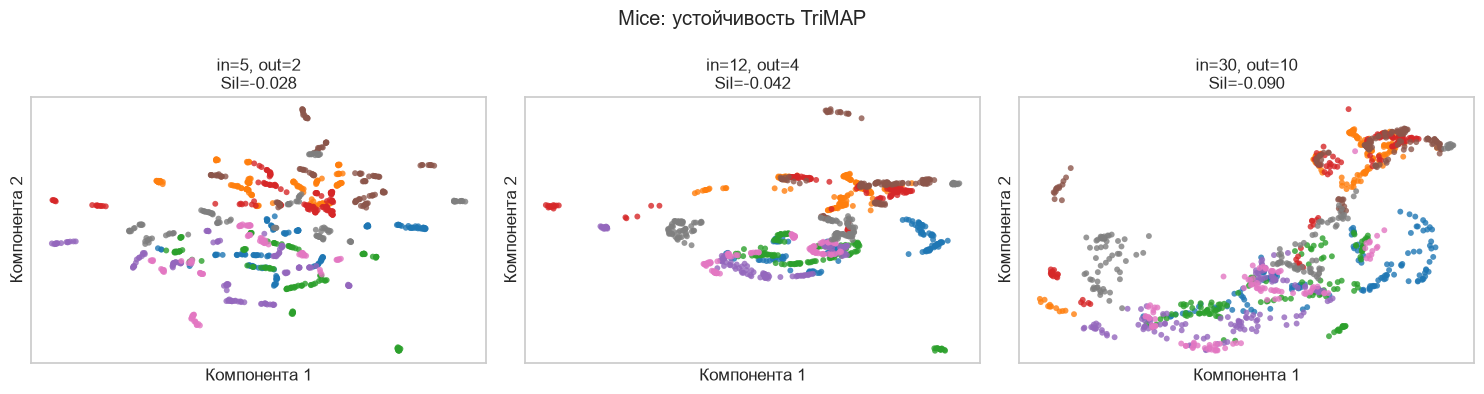

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (n_in, n_out) in zip(axes, trimap_params):
    emb, seconds = run_trimap(X_own_scaled, n_in, n_out)
    sil, _ = embedding_scores(X_own_scaled, emb, y_own)
    plot_embedding(emb, y_own, f"in={n_in}, out={n_out}\nSil={sil:.3f}", ax, False)
fig.suptitle("Mice: устойчивость TriMAP"); plt.tight_layout(); plt.show()

Sample size is smaller than the total number of assigned points, n_neighbors, n_MN, n_FP would be reorganized


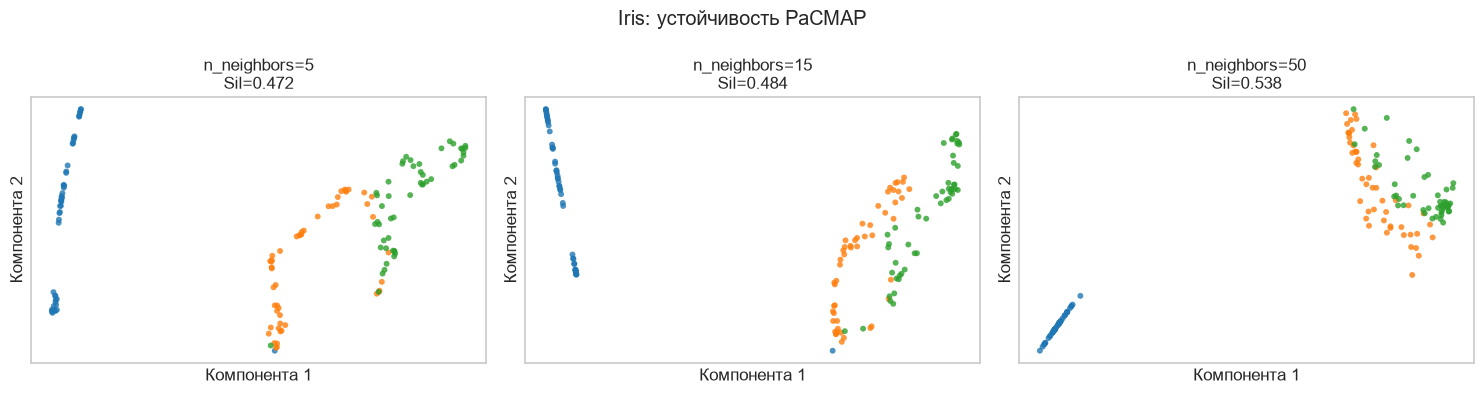

In [20]:
pacmap_neighbors = [5, 15, 50]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, pacmap_neighbors):
    emb, seconds = run_pacmap(X_iris_scaled, n)
    sil, _ = embedding_scores(X_iris_scaled, emb, y_iris)
    plot_embedding(emb, y_iris, f"n_neighbors={n}\nSil={sil:.3f}", ax, False)
fig.suptitle("Iris: устойчивость PaCMAP"); plt.tight_layout(); plt.show()

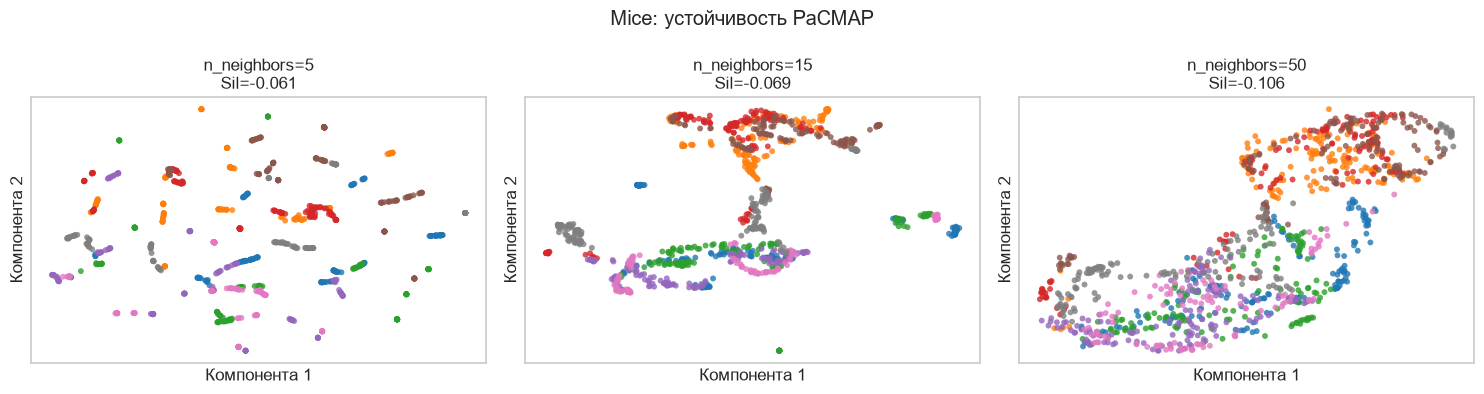

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, pacmap_neighbors):
    emb, seconds = run_pacmap(X_own_scaled, n)
    sil, _ = embedding_scores(X_own_scaled, emb, y_own)
    plot_embedding(emb, y_own, f"n_neighbors={n}\nSil={sil:.3f}", ax, False)
fig.suptitle("Mice: устойчивость PaCMAP"); plt.tight_layout(); plt.show()

C:\Users\1\anaconda3\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
C:\Users\1\anaconda3\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


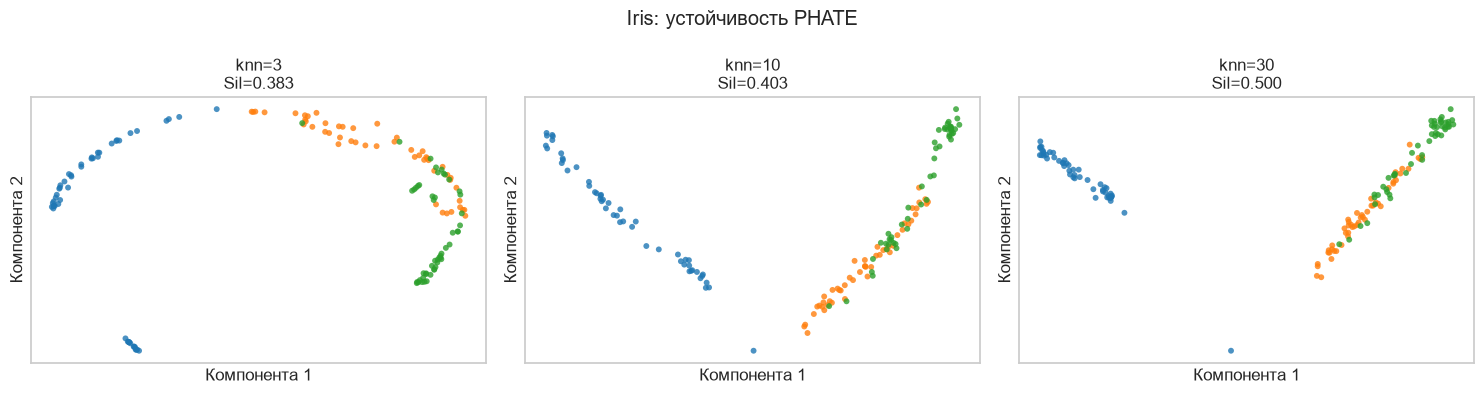

In [22]:
phate_knn = [3, 10, 30]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, phate_knn):
    emb, seconds = run_phate(X_iris_scaled, n)
    sil, _ = embedding_scores(X_iris_scaled, emb, y_iris)
    plot_embedding(emb, y_iris, f"knn={n}\nSil={sil:.3f}", ax, False)
fig.suptitle("Iris: устойчивость PHATE"); plt.tight_layout(); plt.show()

C:\Users\1\anaconda3\Lib\site-packages\phate\phate.py:919: RuntimeWarning: Graph is disconnected with 29 connected components. This may indicate that your knn parameter (currently 3) is too small, or that your data contains distinct clusters. PHATE may not accurately represent relationships between disconnected components.
  warnings.warn(


    SGD-MDS may not have converged: stress changed by 1.2% in final iterations. Consider increasing n_iter or adjusting learning_rate.
    SGD-MDS may not have converged: stress changed by -5.3% in final iterations. Consider increasing n_iter or adjusting learning_rate.
    SGD-MDS may not have converged: stress changed by 3.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.


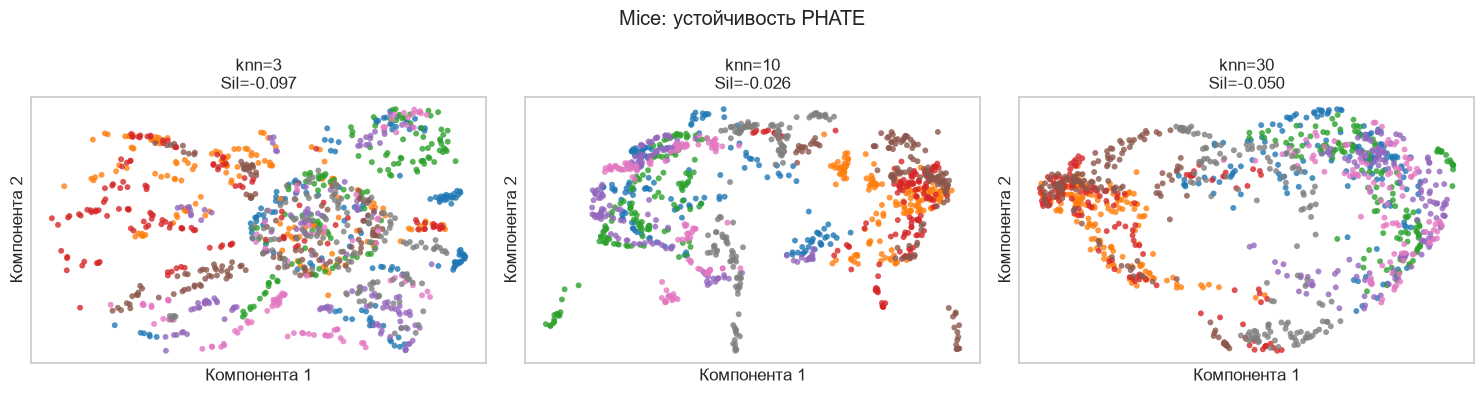

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, phate_knn):
    emb, seconds = run_phate(X_own_scaled, n)
    sil, _ = embedding_scores(X_own_scaled, emb, y_own)
    plot_embedding(emb, y_own, f"knn={n}\nSil={sil:.3f}", ax, False)
fig.suptitle("Mice: устойчивость PHATE"); plt.tight_layout(); plt.show()

Обычно структура UMAP меняется плавнее, кластеры остаются узнаваемыми при разумном диапазоне параметров.

*Задача* Аналогично нужно сделать по одной строке графиков для TriMAP, PaCMAP, PHATE с варьированием ключевого параметра (количество соседей или похожий гиперпараметр) и показать, насколько устойчив рисунок.



| Метод  | Скорость на больших данных                   | Локальное разделение              | Глобальная структура                            | Чувствительность к параметрам                         | Комментарий                                        |
| ------ | -------------------------------------------- | --------------------------------- | ----------------------------------------------- | ----------------------------------------------------- | -------------------------------------------------- |
| t‑SNE  | Низкая l                    | Отличное                   | Слабая                                   | Высокая (perplexity, lr, random_state) aicompetence+2 | Хорошо для локальных кластеров, тяжёлый тюнинг     |
| UMAP   | Высокая l                   | Очень хорошее   | Лучшая, чем у t‑SNE           | Ниже, чем у t‑SNE aicompetence+2                      | Хороший баланс локал/глобал, удобен в практике     |
| TriMAP | Средняя                              | Хорошее                   | Сильный упор на глобальную структуру    | Умеренная                                     | Лучше показывает относительное положение кластеров |
| PaCMAP | Средняя                               | Отличное                   | Хорошее                                  | Умеренная                                      | Часто даёт чёткие кластеры и форму многобразия     |
| PHATE  | Средняя/низкая (зависит от размера)   | Хорошее        | Очень хорошее, особенно для траекторий   | Умеренная                          | Сильный метод для непрерывных переходов            |

# Варианты препроцессинга
*Задача* — явно сравнить, как UMAP и t‑SNE реагируют на разные варианты нормировки и отбора признаков.

## Определяем три сценария
Без масштабирования (сырой набор признаков).

StandardScaler (z‑нормировка).

MinMaxScaler + отбор признаков по дисперсии (эмуляция feature selection).

Задание. Проделать все три сценария. Обучить все модели при разных сценария кластеризации. 
Нужно в результате:
1. описать, какие признаки были отброшены и почему это может влиять на качество кластеризации во вложенном пространстве.
1. сравнить вычислительное время и сделать вывод о масштабируемости методов
1. изменить гиперпараметры (perplexity, n_neighbors, min_dist) и исследовать совместное влияние гиперпараметров и препроцессинга на структуру кластеров.


In [24]:
X_own_raw = X_own.copy()
X_own_standard = X_own_scaled.copy()
X_own_minmax = MinMaxScaler().fit_transform(X_own)
selector = VarianceThreshold(threshold=0.02)
X_own_minmax_selected = selector.fit_transform(X_own_minmax)
preprocessing = {"Без масштабирования": X_own_raw,
                 "StandardScaler": X_own_standard,
                 "MinMax + VarianceThreshold": X_own_minmax_selected}
print({name: data.shape for name, data in preprocessing.items()})

{'Без масштабирования': (1080, 77), 'StandardScaler': (1080, 77), 'MinMax + VarianceThreshold': (1080, 33)}


In [25]:
selected_indices = np.flatnonzero(selector.get_support())
dropped_indices = np.flatnonzero(~selector.get_support())
print("Оставлено признаков:", len(selected_indices), "; отброшено:", len(dropped_indices))

Оставлено признаков: 33 ; отброшено: 44


In [26]:
selected_features = [protein_cols[i] for i in selected_indices]
dropped_features = [protein_cols[i] for i in dropped_indices]
print("Оставленные признаки:", selected_features)
print("Отброшенные признаки:", dropped_features)
display(pd.DataFrame({"Признак": protein_cols, "Дисперсия после MinMax": X_own_minmax.var(axis=0),
                      "Оставлен": selector.get_support()}).sort_values("Дисперсия после MinMax"))

Оставленные признаки: ['NR1_N', 'pCAMKII_N', 'pCREB_N', 'PKCA_N', 'pNR2A_N', 'pPKCAB_N', 'ELK_N', 'ERK_N', 'MEK_N', 'TRKA_N', 'RSK_N', 'APP_N', 'Bcatenin_N', 'SOD1_N', 'RAPTOR_N', 'pP70S6_N', 'NUMB_N', 'pPKCG_N', 'S6_N', 'ADARB1_N', 'ARC_N', 'nNOS_N', 'GluR3_N', 'pCASP9_N', 'PSD95_N', 'SNCA_N', 'Ubiquitin_N', 'pGSK3B_Tyr216_N', 'SHH_N', 'pS6_N', 'EGR1_N', 'H3MeK4_N', 'CaNA_N']
Отброшенные признаки: ['DYRK1A_N', 'ITSN1_N', 'BDNF_N', 'NR2A_N', 'pAKT_N', 'pBRAF_N', 'pELK_N', 'pERK_N', 'pJNK_N', 'pMEK_N', 'pNR1_N', 'pNR2B_N', 'pRSK_N', 'AKT_N', 'BRAF_N', 'CAMKII_N', 'CREB_N', 'GSK3B_N', 'JNK_N', 'MTOR_N', 'P38_N', 'pMTOR_N', 'DSCR1_N', 'AMPKA_N', 'NR2B_N', 'pNUMB_N', 'TIAM1_N', 'P70S6_N', 'pGSK3B_N', 'CDK5_N', 'AcetylH3K9_N', 'RRP1_N', 'BAX_N', 'ERBB4_N', 'Tau_N', 'GFAP_N', 'GluR4_N', 'IL1B_N', 'P3525_N', 'BAD_N', 'BCL2_N', 'pCFOS_N', 'SYP_N', 'H3AcK18_N']


,Признак,Дисперсия после MinMax,Оставлен
51,RRP1_N,0.002235,False
59,GluR4_N,0.003348,False
47,CDK5_N,0.003448,False
9,pELK_N,0.006722,False
5,pAKT_N,0.007628,False
...,...,...,...
17,pPKCAB_N,0.037203,True
48,S6_N,0.039365,True
76,CaNA_N,0.042185,True
46,pPKCG_N,0.043154,True


T-SNE

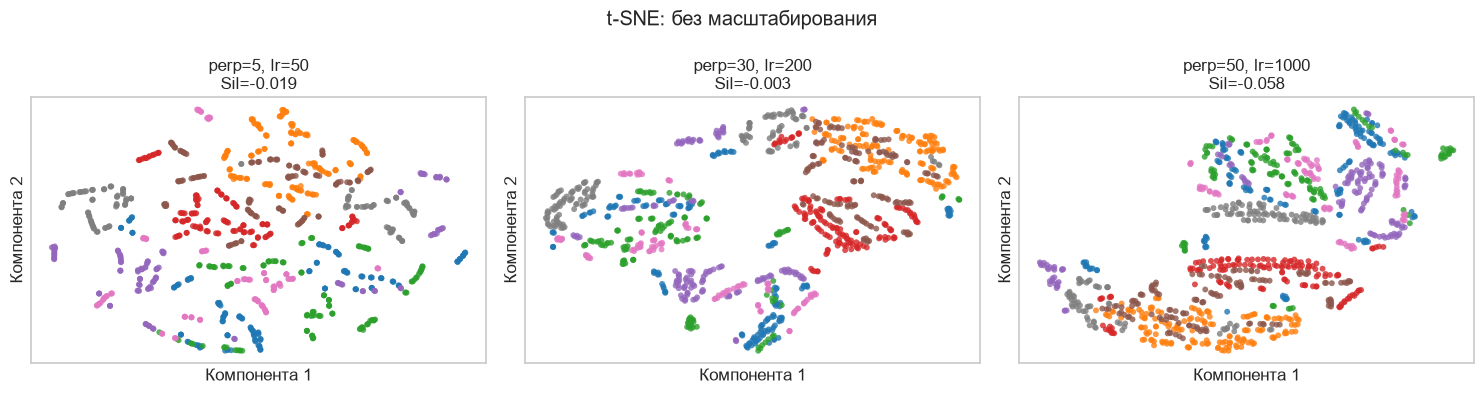

In [27]:
tsne_configs = [(5, 50), (30, 200), (50, 1000)]
preprocess_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (perp, lr) in zip(axes, tsne_configs):
    emb, seconds = run_tsne(X_own_raw, perp, lr); sil, trust = embedding_scores(X_own_raw, emb, y_own)
    preprocess_rows.append(["t-SNE", "Без масштабирования", f"perp={perp}, lr={lr}", sil, trust, seconds])
    plot_embedding(emb, y_own, f"perp={perp}, lr={lr}\nSil={sil:.3f}", ax, False)
fig.suptitle("t-SNE: без масштабирования"); plt.tight_layout(); plt.show()

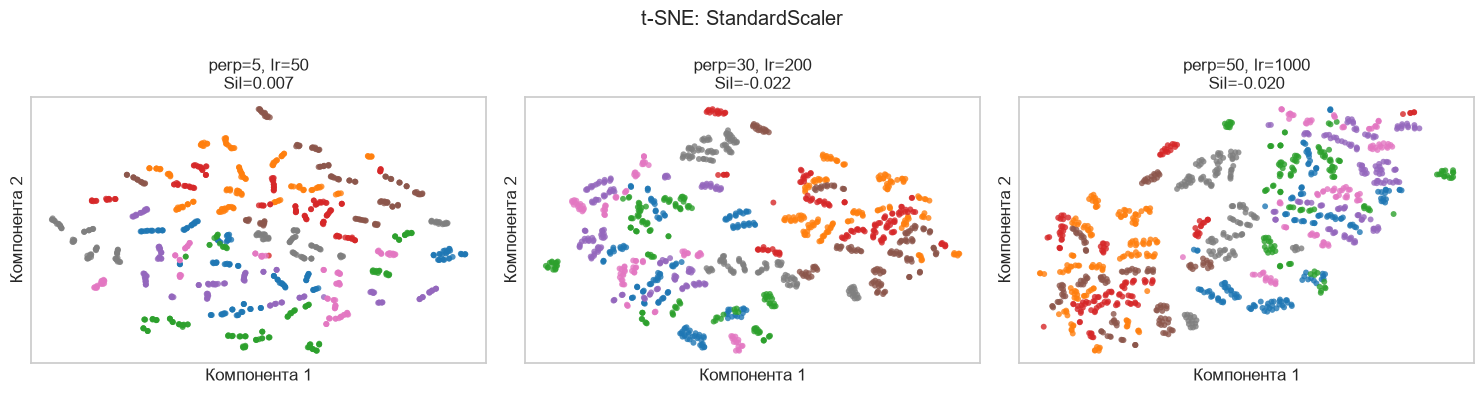

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (perp, lr) in zip(axes, tsne_configs):
    emb, seconds = tsne_cache[("Mice", perp, lr)]; sil, trust = embedding_scores(X_own_standard, emb, y_own)
    preprocess_rows.append(["t-SNE", "StandardScaler", f"perp={perp}, lr={lr}", sil, trust, seconds])
    plot_embedding(emb, y_own, f"perp={perp}, lr={lr}\nSil={sil:.3f}", ax, False)
fig.suptitle("t-SNE: StandardScaler"); plt.tight_layout(); plt.show()

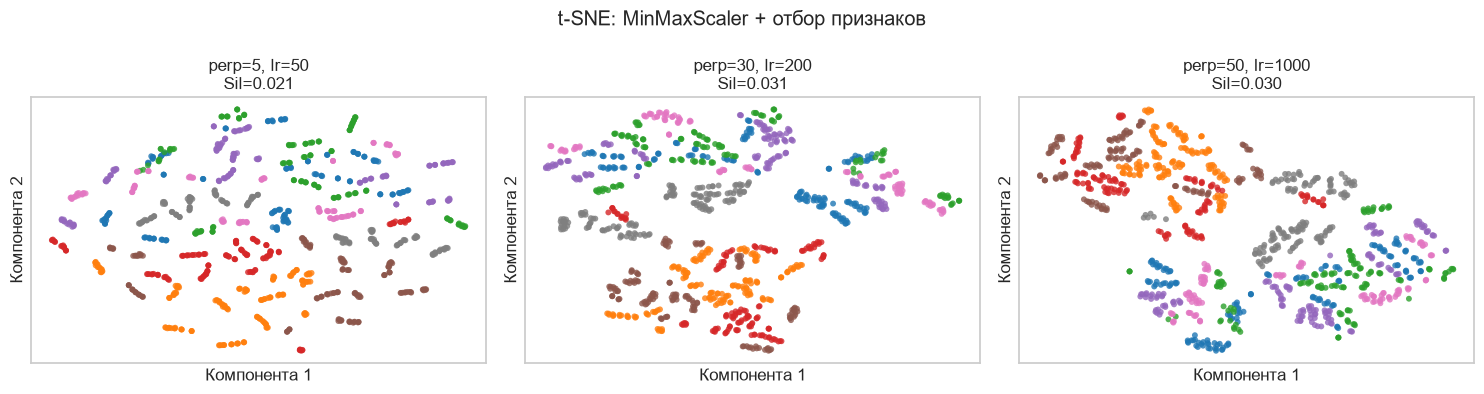

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (perp, lr) in zip(axes, tsne_configs):
    emb, seconds = run_tsne(X_own_minmax_selected, perp, lr); sil, trust = embedding_scores(X_own_minmax_selected, emb, y_own)
    preprocess_rows.append(["t-SNE", "MinMax + VarianceThreshold", f"perp={perp}, lr={lr}", sil, trust, seconds])
    plot_embedding(emb, y_own, f"perp={perp}, lr={lr}\nSil={sil:.3f}", ax, False)
fig.suptitle("t-SNE: MinMaxScaler + отбор признаков"); plt.tight_layout(); plt.show()

UMAP

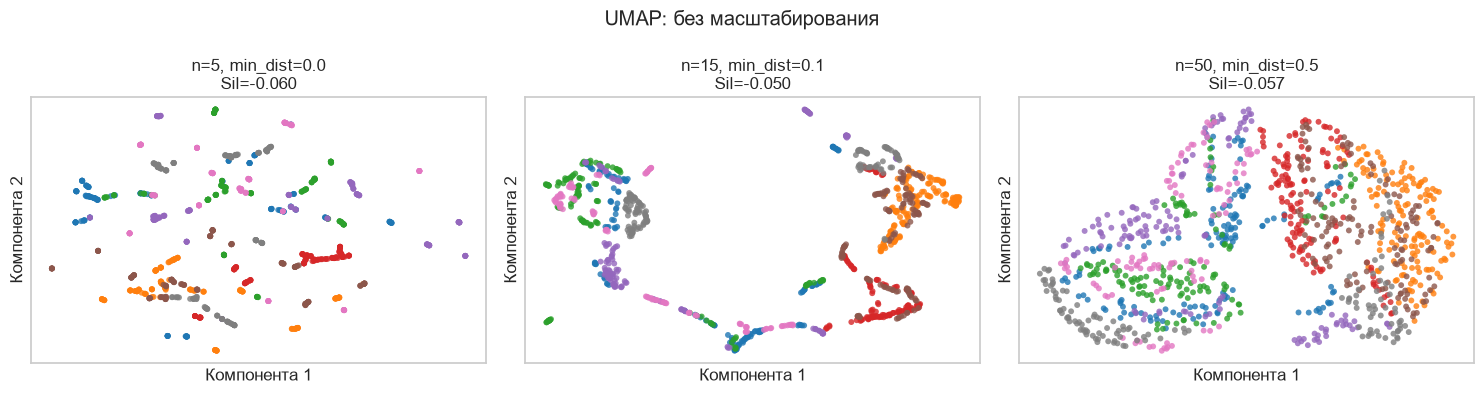

In [30]:
umap_configs = [(5, 0.0), (15, 0.1), (50, 0.5)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (n, md) in zip(axes, umap_configs):
    emb, seconds = run_umap(X_own_raw, n, md); sil, trust = embedding_scores(X_own_raw, emb, y_own)
    preprocess_rows.append(["UMAP", "Без масштабирования", f"n={n}, min_dist={md}", sil, trust, seconds])
    plot_embedding(emb, y_own, f"n={n}, min_dist={md}\nSil={sil:.3f}", ax, False)
fig.suptitle("UMAP: без масштабирования"); plt.tight_layout(); plt.show()

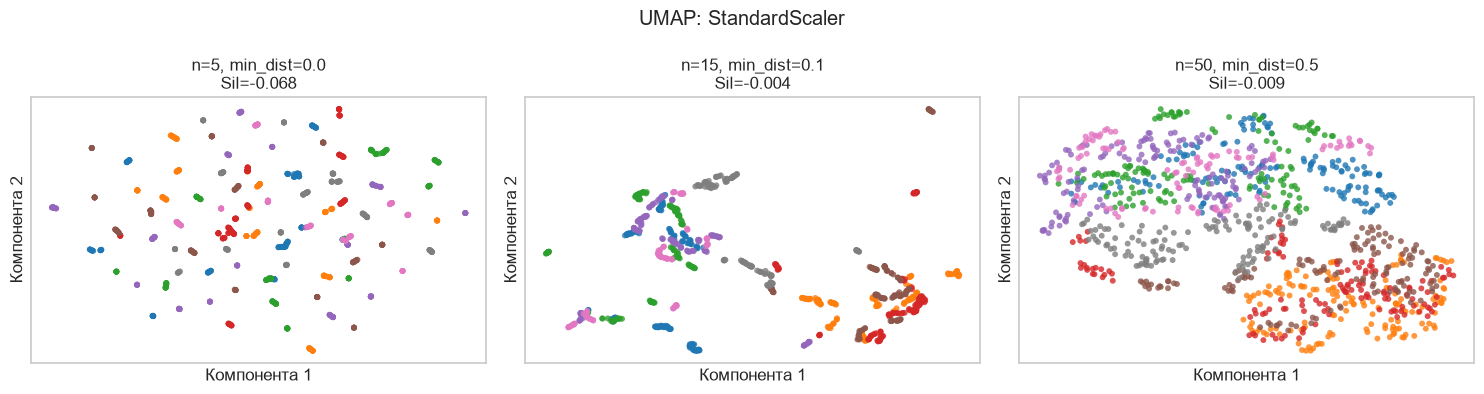

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (n, md) in zip(axes, umap_configs):
    emb, seconds = umap_cache[("Mice", n, md)]; sil, trust = embedding_scores(X_own_standard, emb, y_own)
    preprocess_rows.append(["UMAP", "StandardScaler", f"n={n}, min_dist={md}", sil, trust, seconds])
    plot_embedding(emb, y_own, f"n={n}, min_dist={md}\nSil={sil:.3f}", ax, False)
fig.suptitle("UMAP: StandardScaler"); plt.tight_layout(); plt.show()

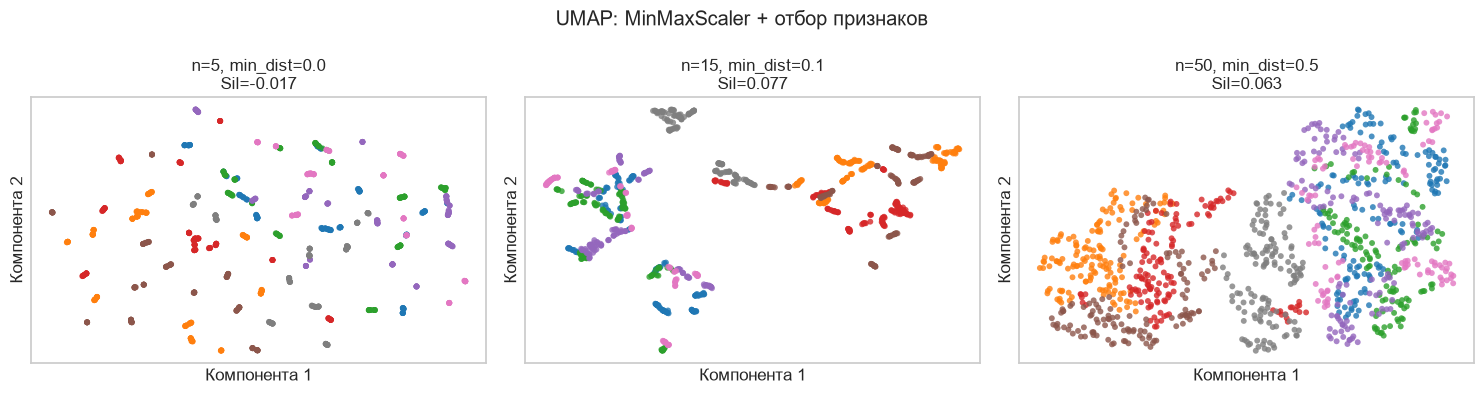

,Метод,Препроцессинг,Параметры,Silhouette,Trustworthiness@10,"Время, с"
0,t-SNE,Без масштабирования,"perp=5, lr=50",-0.019,0.985,4.81
1,t-SNE,Без масштабирования,"perp=30, lr=200",-0.003,0.994,6.03
2,t-SNE,Без масштабирования,"perp=50, lr=1000",-0.058,0.993,8.71
3,t-SNE,StandardScaler,"perp=5, lr=50",0.007,0.984,4.41
4,t-SNE,StandardScaler,"perp=30, lr=200",-0.022,0.990,7.15
5,t-SNE,StandardScaler,"perp=50, lr=1000",-0.020,0.984,8.60
6,t-SNE,MinMax + VarianceThreshold,"perp=5, lr=50",0.021,0.992,4.60
7,t-SNE,MinMax + VarianceThreshold,"perp=30, lr=200",0.031,0.995,6.91
8,t-SNE,MinMax + VarianceThreshold,"perp=50, lr=1000",0.030,0.989,8.19
9,UMAP,Без масштабирования,"n=5, min_dist=0.0",-0.060,0.966,2.90


In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (n, md) in zip(axes, umap_configs):
    emb, seconds = run_umap(X_own_minmax_selected, n, md); sil, trust = embedding_scores(X_own_minmax_selected, emb, y_own)
    preprocess_rows.append(["UMAP", "MinMax + VarianceThreshold", f"n={n}, min_dist={md}", sil, trust, seconds])
    plot_embedding(emb, y_own, f"n={n}, min_dist={md}\nSil={sil:.3f}", ax, False)
fig.suptitle("UMAP: MinMaxScaler + отбор признаков"); plt.tight_layout(); plt.show()
preprocess_results = pd.DataFrame(preprocess_rows, columns=["Метод", "Препроцессинг", "Параметры", "Silhouette", "Trustworthiness@10", "Время, с"])
display(preprocess_results.style.format({"Silhouette": "{:.3f}", "Trustworthiness@10": "{:.3f}", "Время, с": "{:.2f}"}))

**Выводы по препроцессингу и масштабируемости**

Масштабирование существенно влияет на обе модели, поскольку они строят соседства по расстояниям. После MinMaxScaler и VarianceThreshold с порогом 0.02 осталось 33 из 77 белковых признаков, то есть было удалено 44 признака. 

Для t-SNE лучший вариант предобработки — MinMaxScaler + VarianceThreshold при perplexity=30 и learning_rate=200: silhouette=0.031 и trustworthiness=0.995. Для тех же параметров на сырых данных silhouette=-0.003, после StandardScaler — -0.022. Для UMAP лучший результат также получен после MinMaxScaler + VarianceThreshold при n_neighbors=15 и min_dist=0.1: silhouette=0.077 и trustworthiness=0.992; на сырых и стандартизованных данных silhouette для этой конфигурации равен -0.050 и -0.004 соответственно.

В базовом сравнении пяти методов на Iris наибольший silhouette показал t-SNE (0.533), а PaCMAP оказался самым быстрым. На Mice ни один метод не разделил восемь классов хорошо: лучший базовый silhouette у UMAP равен -0.004, а максимальный trustworthiness у t-SNE равен 0.990. Это показывает, что сохранение локального соседства не гарантирует совпадения двумерных групп с известными классами.